# Assignment 3 — Convolution and Attention, from Scratch
**Computer Vision** &nbsp;·&nbsp; Due: **Friday 23 October 2026**, 11:59 PM &nbsp;·&nbsp; 54 points

Assignment 2 built a fully connected network that treated an image as a flat vector of 784
numbers, with no idea that two of those numbers might be neighbours. Part A builds the
architecture that does know about spatial structure, and knows it because the structure is
**hard-coded into the shape of the layer**. Part B is about the alternative: attention, which
assumes nothing about space and has to be told where things are.

| Part | Topic | Points |
|---|---|---|
| **A** | A convolutional network in NumPy | 35 |
| **B** | Attention | 19 |

**Reading.** Chapter 24 (Convolutional Neural Nets) for Part A; Chapter 26 (Transformers) for
Part B, of *Foundations of Computer Vision*.

**What is provided.** `a3utils.py` contains the layers you wrote in Assignment 2 — `Linear`,
`ReLU`, `SoftmaxCrossEntropy`, `MLP` and `train` — so that this assignment stands on its own
and a bug in your Assignment 2 code cannot follow you here. Use them; do not rewrite them.
`Linear` has been generalised to apply to the last axis of an array with any number of leading
axes, so the same class serves a batch of vectors and a batch of token sequences. For 2-D input
it is identical to the version you wrote.

**Rules for the code.**
- Use **NumPy only**. No PyTorch, TensorFlow, JAX, autograd libraries or anything that
  computes gradients for you.
- Edit only the cells marked `# YOUR CODE HERE` and the *Your answer* cells.
- Every layer comes with a **gradient check**. Get it to print `PASS` before moving on: a layer
  that fails its check will make every later part fail in confusing ways.
- The layer protocol is the one from Assignment 2. `forward(x)` returns the output and saves
  whatever `backward` will need; `backward(g_out)` receives $\partial J/\partial x_\text{out}$,
  sets the gradient of each parameter, and returns $\partial J/\partial x_\text{in}$;
  `params()` lists `(name, parameter, gradient)` triples.

**Suggested schedule.** Part A is most of the work; start it in week 1. B1 to B3 are pen and
paper and can be done away from a computer.

**AI tools.** If you use a coding assistant or language model, add a short note at the end
saying what you used and for what. This is not penalised; failing to disclose it is.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

from a3utils import (load_mnist, batches, evaluate, grad_check, grad_check_model,
                     Linear, ReLU, SoftmaxCrossEntropy, MLP, train,   # from Assignment 2
                     LayerNorm, Residual, MeanPool)                   # referred to in Part B

np.set_printoptions(precision=4, suppress=True)

---
# Part A — A convolutional network in NumPy &nbsp; [35 points]

Now images keep their spatial shape: a batch is a 4-D array of shape `(B, C, H, W)`.

Loops over pixels in Python will be far too slow to train on MNIST. Use
`sliding_window_view` (already imported). For a padded input `xp` of shape `(B, C, H, W)`,

```python
win = sliding_window_view(xp, (k, k), axis=(2, 3))     # shape (B, C, H', W', k, k)
```

gives every $k\times k$ window at once, and `np.einsum` can then combine the windows with the
kernel in a single call. Pass `optimize=True` to `einsum` for speed.

## A1. Convolutional layer &nbsp; [14 points]

Implement `forward` **[5]** and `backward` **[9]** for a stride-1 convolution with zero padding.
As in Chapter 24, this is really cross-correlation:

$$x_{\text{out}}[b, o, n, m] = b_o + \sum_{c}\sum_{i,j} W[o, c, i, j]\; x_{\text{pad}}[b, c, n+i, m+j].$$

`backward` must set `self.dW` and `self.db` and return $\partial J/\partial x_{\text{in}}$.

*Hints for backward.*
- `self.dW`: by Assignment 2, Question A2(b), each weight collects a contribution from every
  position and every example. It is again a sum over windows.
- $\partial J / \partial x_{\text{in}}$: there are two good approaches.
  1. **Scatter-add**: start from zeros of the padded shape, and add each output gradient back onto
     the $k\times k$ window of inputs that produced it. Loop over the $k^2$ kernel offsets rather than
     over pixels, so there are only 9 iterations for a $3\times 3$ kernel.
  2. **Full convolution**: it is a fact, which you may use without proof, that
     $\partial J / \partial x_{\text{pad}}$ is the gradient `g_out`, padded by $k-1$ on every side and
     cross-correlated with the kernel **flipped** in both spatial directions, `W[:, :, ::-1, ::-1]`,
     with the roles of the input and output channels exchanged.

  Either way, remember to crop away the padding at the end.

In [20]:
class Conv2D:
    """
    x : (B, C_in, H, W)   W : (C_out, C_in, k, k)   b : (C_out,)
    Stride 1, zero padding of `pad` on each side. With pad = (k-1)//2 the output is also H x W.
    """
    def __init__(self, c_in, c_out, k, pad, rng):
        self.W = rng.standard_normal((c_out, c_in, k, k)) * np.sqrt(2.0 / (c_in * k * k))
        self.b = np.zeros(c_out)
        self.k, self.pad = k, pad
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x):
        p = self.pad
        xp = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p))) # pad only two spatial axes
        win = sliding_window_view(xp, (self.k, self.k), axis=(2, 3)) # type: ignore
        self.xp, self.win = xp, win # save for backward
        out = np.einsum('bcnmij,ocij->bonm', win, self.W, optimize=True)
        return out + self.b[:, None, None] # make b broadcast over B, H', W'

    def backward(self, g_out):
        p = self.pad
        H = self.xp.shape[2] - 2 * p
        W_in = self.xp.shape[3] - 2 * p
        self.dW = np.einsum('bonm,bcnmij->ocij', g_out, self.win, optimize=True)
        self.db = g_out.sum(axis=(0, 2, 3))
        dxp = np.zeros_like(self.xp)
        Hp, Wp = g_out.shape[2], g_out.shape[3]
        for i in range(self.k):
            for j in range(self.k):
                dxp[:, :, i:i+Hp, j:j+Wp] += np.einsum('bonm,oc->bcnm', g_out, self.W[:, :, i, j])
        return dxp[:, :, p:p+H, p:p+W_in]

    def params(self):
        return [("W", self.W, self.dW), ("b", self.b, self.db)]

In [21]:
rng = np.random.default_rng(5)
print("Conv2D, padding 1:")
ok_A1a = grad_check(Conv2D(3, 4, 3, 1, rng), rng.standard_normal((2, 3, 6, 6)))
print("Conv2D, padding 0:")
ok_A1b = grad_check(Conv2D(2, 3, 3, 0, rng), rng.standard_normal((2, 2, 7, 7)))

Conv2D, padding 1:
     input   relative error 6.72e-10   PASS
         W   relative error 8.10e-11   PASS
         b   relative error 2.00e-10   PASS
Conv2D, padding 0:
     input   relative error 3.87e-10   PASS
         W   relative error 9.77e-11   PASS
         b   relative error 1.36e-10   PASS


## A2. Max pooling &nbsp; [6 points]

Implement non-overlapping $2\times2$ max pooling. You may assume $H$ and $W$ are even.

*Hints.* `x.reshape(B, C, H//2, 2, W//2, 2)` puts each $2\times2$ block on its own pair of axes,
so the forward pass is a single `max`. For the backward pass, the gradient flows only to the
position that won the max in each block, and is zero everywhere else.

In [22]:
class MaxPool2D:
    def forward(self, x):
        B, C, H, W = x.shape
        xr = x.reshape(B, C, H // 2, 2, W // 2, 2)
        out = xr.max(axis=(3, 5)) # (B, C, H/2, W/2)
        self.mask = (xr == out[:, :, :, None, :, None]) # true where the block's max sits
        self.shape = x.shape
        return out

    def backward(self, g_out):
        g = g_out[:, :, :, None, :, None] * self.mask # spread g_out over each block, keep winner
        return g.reshape(self.shape) # back to (B, C, H, W)

    def params(self):
        return []

In [23]:
rng = np.random.default_rng(6)
print("MaxPool2D:")
ok_A2 = grad_check(MaxPool2D(), rng.standard_normal((2, 3, 6, 6)))

MaxPool2D:
     input   relative error 3.38e-10   PASS


## A3. Flatten &nbsp; [2 points]

Implement `Flatten`, which turns `(B, C, H, W)` into `(B, C*H*W)` so that a `Linear` layer can
follow the convolutions.

In [24]:
class Flatten:
    def forward(self, x):
        self.shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, g_out):
        return g_out.reshape(self.shape)

    def params(self):
        return []

In [25]:
rng = np.random.default_rng(7)
print("Flatten:")
ok_A3 = grad_check(Flatten(), rng.standard_normal((2, 3, 4, 4)))

Flatten:
     input   relative error 2.86e-10   PASS


## A4. Training the CNN &nbsp; [8 points]

The architecture is given: two blocks of convolution, ReLU and max pooling, then a linear
classifier. Because `CNN` inherits from `MLP`, the `backward`, `step` and `train` of
Assignment 2 all work unchanged.

Run the gradient check, then train for 3 epochs. A correct implementation reaches **at least
97%**. Each epoch should take a minute or two; while debugging, train on a subset such as
`x_train[:5000]` to get quick feedback.

In the answer cell, report your final test accuracy and include the loss curve.

In [26]:
class CNN(MLP):
    """conv(1->8) relu pool   conv(8->16) relu pool   flatten   linear(784->10)"""
    def __init__(self, rng):
        self.layers = [Conv2D(1, 8, 3, 1, rng),  ReLU(), MaxPool2D(),      # 28x28 -> 14x14
                       Conv2D(8, 16, 3, 1, rng), ReLU(), MaxPool2D(),      # 14x14 ->  7x7
                       Flatten(), Linear(16 * 7 * 7, 10, rng)]
        self.loss = SoftmaxCrossEntropy()

In [27]:
rng = np.random.default_rng(8)
print("Whole CNN, loss included:")
ok_A4 = grad_check_model(CNN(rng), rng.standard_normal((2, 1, 28, 28)), rng.integers(0, 10, 2))

Whole CNN, loss included:
  param  0 (W, shape   (8, 1, 3, 3))   relative error 1.29e-09   PASS
  param  1 (b, shape           (8,))   relative error 9.17e-10   PASS
  param  2 (W, shape  (16, 8, 3, 3))   relative error 4.23e-10   PASS
  param  3 (b, shape          (16,))   relative error 5.02e-10   PASS
  param  4 (W, shape      (10, 784))   relative error 7.77e-11   PASS
  param  5 (b, shape          (10,))   relative error 3.55e-10   PASS


train (60000, 1, 28, 28)  test (10000, 1, 28, 28)
epoch 1:  last batch loss 0.0990,  test accuracy 0.9633
epoch 2:  last batch loss 0.0859,  test accuracy 0.9744
epoch 3:  last batch loss 0.1359,  test accuracy 0.9781


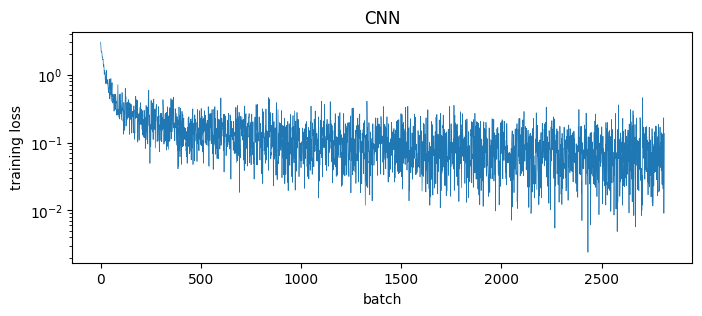

final CNN test accuracy: 0.9781


In [28]:
x_train, y_train, x_test, y_test = load_mnist(flat=False)
print("train", x_train.shape, " test", x_test.shape)

rng = np.random.default_rng(0)
cnn = CNN(rng)
hist_cnn = train(cnn, x_train, y_train, x_test, y_test, epochs=3, lr=0.05, batch_size=64, rng=rng)

plt.figure(figsize=(8, 3))
plt.plot(hist_cnn, lw=0.5)
plt.xlabel("batch"); plt.ylabel("training loss"); plt.title("CNN"); plt.yscale("log")
plt.show()
acc_cnn = evaluate(cnn, x_test, y_test)
print(f"final CNN test accuracy: {acc_cnn:.4f}")

### Your answer — A4

The final CNN test accuracy is $0.9781=97.81\%$

## A5. The CNN against the MLP &nbsp; [5 points]

The first cell below trains the Assignment 2 baseline — the same 784-128-64-10 MLP, on the same
data — and the second counts the parameters of both networks.

Compare the two on **number of parameters** and **test accuracy**. Explain the result using the
two properties from Chapter 24, §24.10: patches are processed independently, and processed
identically. Which of these is responsible for the reduction in parameters, and what assumption
about images does each one encode?

In [29]:
xf_train, yf_train, xf_test, yf_test = load_mnist(flat=True)   # the MLP wants flat vectors

rng = np.random.default_rng(0)
mlp = MLP([784, 128, 64, 10], rng)
hist_mlp = train(mlp, xf_train, yf_train, xf_test, yf_test,
                 epochs=3, lr=0.1, batch_size=64, rng=rng)
acc_mlp = evaluate(mlp, xf_test, yf_test)
print(f"final MLP test accuracy: {acc_mlp:.4f}")

epoch 1:  last batch loss 0.1393,  test accuracy 0.9444
epoch 2:  last batch loss 0.0231,  test accuracy 0.9595
epoch 3:  last batch loss 0.0732,  test accuracy 0.9693
final MLP test accuracy: 0.9693


In [30]:
n_mlp = sum(p.size for _, p, _ in mlp.params())
n_cnn = sum(p.size for _, p, _ in cnn.params())
print(f"MLP: {n_mlp:7,d} parameters,  test accuracy {acc_mlp:.4f}")
print(f"CNN: {n_cnn:7,d} parameters,  test accuracy {acc_cnn:.4f}")
print(f"ratio: the MLP has {n_mlp / n_cnn:.1f} times as many parameters")

MLP: 109,386 parameters,  test accuracy 0.9693
CNN:   9,098 parameters,  test accuracy 0.9781
ratio: the MLP has 12.0 times as many parameters


### Your answer — A5

*Write your answer here. Use LaTeX for mathematics, e.g. `$\frac{\partial J}{\partial z}$`.*

---
# Part B — Attention &nbsp; [19 points]

The convolution of Part A got its efficiency by *assuming* that an image is local and
translation invariant. A transformer assumes neither. It cuts the image into patches, calls each
patch a **token**, and lets every token look at every other token through an attention layer
whose weights are computed from the data at run time.

Throughout Part B a batch of tokens is an array of shape `(B, N, d)`: `B` examples, `N` tokens
each, `d` features per token. One head of self-attention, Chapter 26 §26.3, is

$$Q = X W_q^\top,\qquad K = X W_k^\top,\qquad V = X W_v^\top,$$
$$S = \frac{QK^\top}{\sqrt{m}},\qquad A = \operatorname{softmax}_{\text{rows}}(S),
  \qquad X_{\text{out}} = A V,$$

where $X$ is $N \times d$, each projection matrix is $m \times d$, and $S$ and $A$ are
$N \times N$.

The architecture these pieces are assembled into — the vision transformer of Chapter 26 §26.6 —
is this:

> patchify &rarr; linear embedding &rarr; positional codes
> &rarr; residual(layernorm, multi-head attention)
> &rarr; residual(layernorm, MLP)
> &rarr; layernorm &rarr; mean over tokens &rarr; linear classifier

We are not building it here; the point of Part B is to understand **why** it is built that way,
because almost every decision in that line is forced by a property of attention that you can
derive in a few lines. B1 to B3 are those derivations, and each one refers to the architecture
above, so read it before you start. `LayerNorm`, `Residual` and `MeanPool` are in `a3utils.py`
if you want to see what the named pieces actually do — `Residual.backward` in particular is two
lines and worth a look.

B1 to B3 are pen and paper; B4 is a short implementation.

## B1. Attention is a weighted average &nbsp; [5 points]

Write $a_n^\top$ for the $n$-th row of $A$ and $v_j^\top$ for the $j$-th row of $V$.

**(a) [2]** Show that every row of $A$ has non-negative entries that sum to one, whatever $S$ is.

**(b) [2]** Hence write the $n$-th output token as a combination of the value vectors, and state
what set the output is confined to. (The set has a name; it is determined by $v_1,\dots,v_N$ and
does not depend on $S$ at all.) One consequence: attention on its own cannot produce a token that
is more extreme than every token it is given. Which later component of the block can?

**(c) [1]** At initialisation the projection matrices are small, so every entry of $S$ is close
to zero. What is $A$ then, and what operation is the attention layer performing on the tokens?

### Your answer — B1

*Write your answer here. Use LaTeX for mathematics, e.g. `$\frac{\partial J}{\partial z}$`.*

## B2. Why divide by $\sqrt{m}$ &nbsp; [5 points]

**(a) [3]** Let $q, k \in \mathbb{R}^m$ be independent random vectors whose entries are
independent, have zero mean and unit variance. Show that
$$\mathbb{E}[q^\top k] = 0 \qquad\text{and}\qquad \operatorname{Var}[q^\top k] = m .$$

**(b) [2]** So the *unscaled* logits of one row have standard deviation $\sqrt{m}$. Take
$m = 64$ and suppose two logits in a row differ by two standard deviations. Ignoring the other
entries of the row, compute the softmax weight the smaller one receives. Then use
$$\frac{\partial p_i}{\partial s_j} = p_i(\delta_{ij} - p_j)$$
to say what has happened to the gradient reaching that logit, and explain in one sentence why
dividing by $\sqrt{m}$ prevents it.

### Your answer — B2

*Write your answer here. Use LaTeX for mathematics, e.g. `$\frac{\partial J}{\partial z}$`.*

## B3. Permutation equivariance, and why positional codes exist &nbsp; [5 points]

Let $P$ be an $N \times N$ permutation matrix, so that $PX$ is $X$ with its rows (its tokens)
reordered, and $P^\top P = I$.

**(a) [3]** Show that one head of self-attention is **equivariant** to this reordering:
$$\text{attention}(PX) = P \cdot \text{attention}(X).$$
Work through $Q$, $K$, $S$, $A$ and the output in turn. You will need the fact that applying the
softmax to each row of $PSP^\top$ gives $PAP^\top$; say in one line why that is true.

**(b) [2]** The architecture ends with `MeanPool`, which averages over tokens and is therefore
permutation **invariant**. Every layer in between — `LayerNorm`, the per-token MLP, the residual
additions, the embedding `Linear` — acts on one token at a time. Combine this with part (a) to
say exactly what the network would predict for an image whose patches had been shuffled, if the
positional codes were removed. Be precise about the word *exactly*: is the claim that the two
predictions are close, or that they are identical? Say which, and why.

Your answer is a claim about a real network that can be checked by running it, so make it sharp
enough to be wrong.

### Your answer — B3

*Write your answer here. Use LaTeX for mathematics, e.g. `$\frac{\partial J}{\partial z}$`.*

## B4. Row softmax &nbsp; [4 points]

Implement the softmax applied independently to each row — that is, along the **last** axis of an
array with any number of leading axes, so that the same layer serves logits of shape `(B, K)` and
attention scores of shape `(B, N, N)`.

The backward pass is Assignment 2, Question A1, lifted to many rows at once. For one row,
$$\frac{\partial p_i}{\partial s_j} = p_i(\delta_{ij} - p_j)
\qquad\Longrightarrow\qquad
\left(\frac{\partial J}{\partial s}\right)_i = p_i\Big(g_i - \sum_j g_j p_j\Big),$$
where $g = \partial J/\partial p$. The sum is **one scalar per row**, so you can compute this
without ever forming the $n \times n$ Jacobian. That matters more here than it did in Assignment
2: inside an attention layer this softmax is applied to an $N \times N$ score matrix for every
example in the batch, so the explicit Jacobians would be an $N \times N \times N$ array per
example — at $N = 16$ and a batch of 64, a quarter of a million numbers per layer, to compute
something that needs one scalar per row.

Use the stability trick from Assignment 2, Question A3: subtract each row's maximum first.

In [ ]:
class RowSoftmax:
    """
    Softmax along the LAST axis, applied independently to every row.
    x : (..., n)  ->  p : (..., n), each row non-negative and summing to 1.
    """
    def forward(self, x):
        # YOUR CODE HERE
        raise NotImplementedError

    def backward(self, g_out):
        # YOUR CODE HERE
        raise NotImplementedError

    def params(self):
        return []

In [ ]:
rng = np.random.default_rng(10)
print("RowSoftmax on a matrix of logits:")
ok_B4a = grad_check(RowSoftmax(), rng.standard_normal((4, 6)))
print("RowSoftmax on a batch of attention score matrices:")
ok_B4b = grad_check(RowSoftmax(), rng.standard_normal((2, 5, 5)))

# B1(a) says every row must sum to 1 whatever the scores are. That is a property the gradient
# checker cannot test, so test it here -- including on scores large enough to overflow exp()
# if you did not subtract the row maximum.
sm = RowSoftmax()
print("ordinary scores, rows sum to 1:",
      np.allclose(sm.forward(rng.standard_normal((2, 5, 5))).sum(axis=-1), 1.0))
print("scores of size 1000, rows sum to 1:",
      np.allclose(sm.forward(1000 * rng.standard_normal((2, 5, 5))).sum(axis=-1), 1.0))

---
## Submission

Submit this notebook, **executed from top to bottom** with all outputs visible
(*Kernel → Restart & Run All*), together with `a3utils.py`. Every gradient check should print
`PASS`.

A full run takes about three minutes, almost all of it the CNN at roughly a minute per epoch.

**AI tool disclosure** (if applicable):